# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import OverheadMNISTDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader
import numpy as np

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/overhead-mnist/train/",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = OverheadMNISTDataset(dataset_config)

## Show images from the dataset

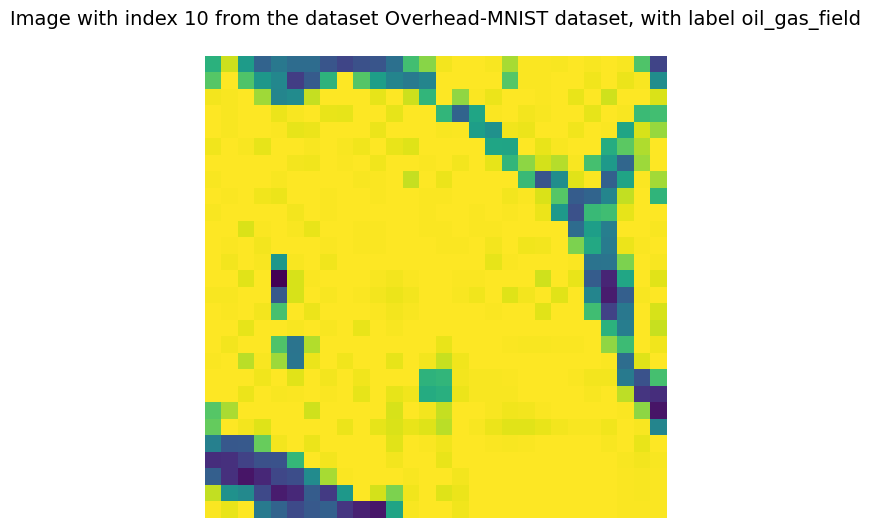

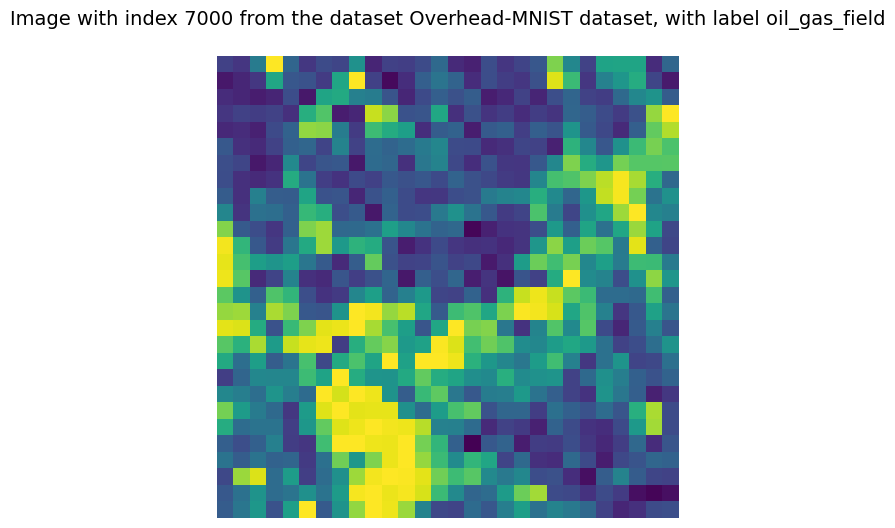

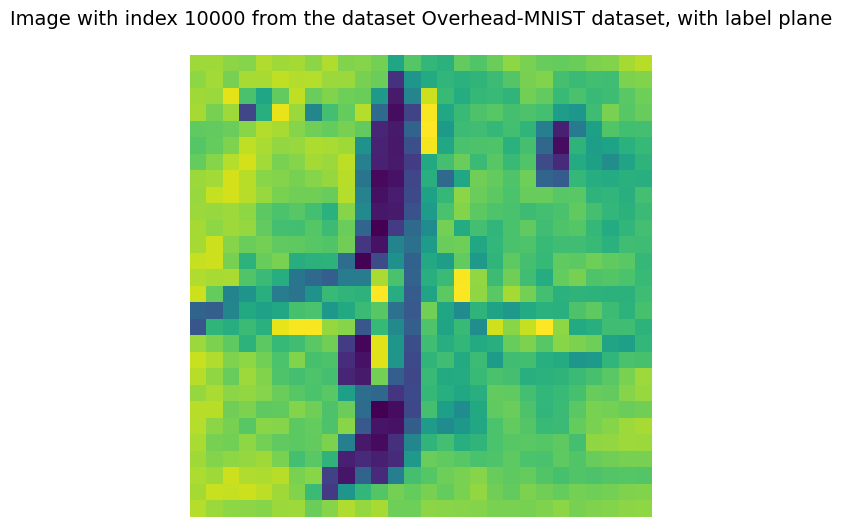

In [11]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(7000)
fig3 = dataset.show_image(10000)

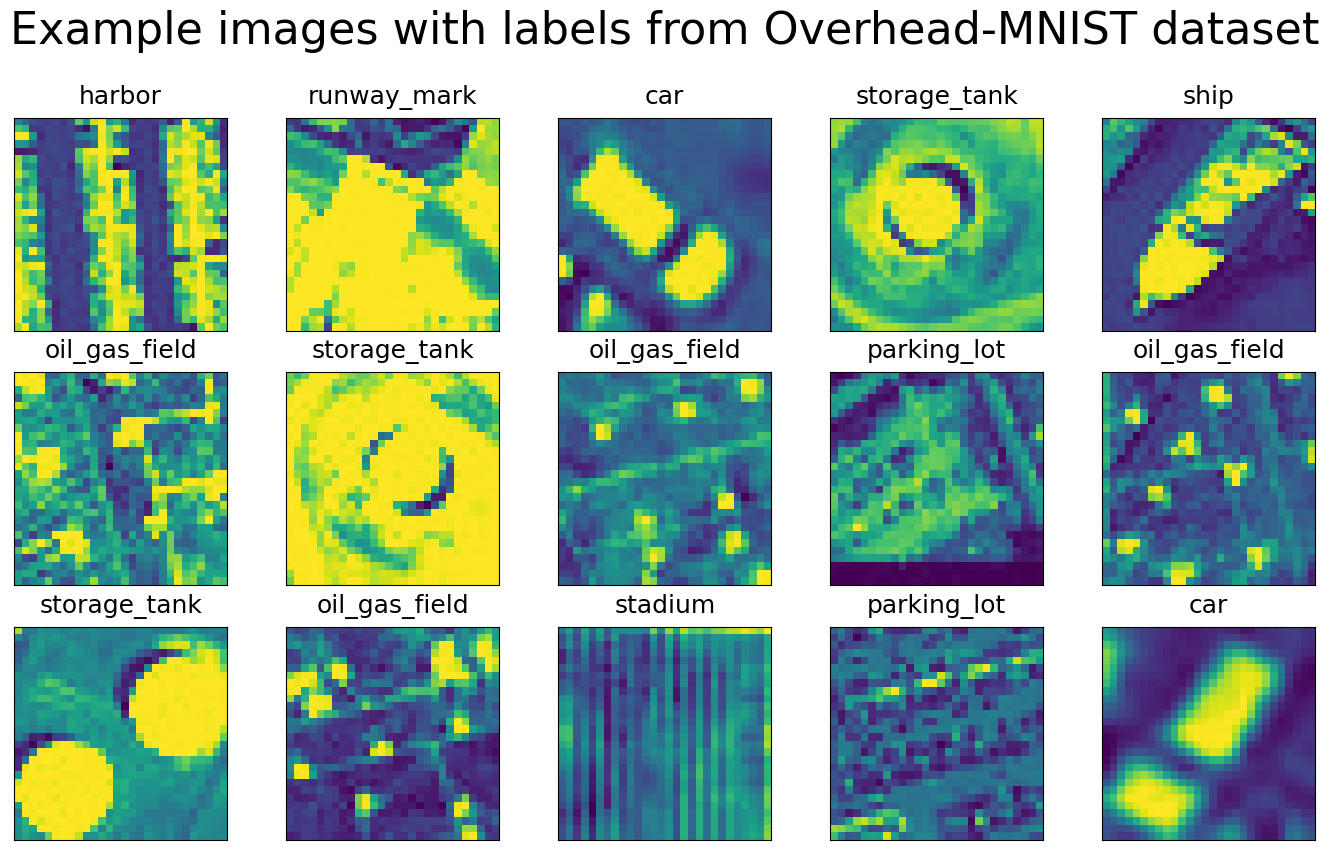

In [12]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [16]:
dataset.data_distribution_table()

,Label,Count
0,car,7116
1,harbor,7119
2,helicopter,5250
3,oil_gas_field,7113
4,parking_lot,7111
5,plane,7124
6,runway_mark,6423
7,ship,7124
8,stadium,6756
9,storage_tank,7121


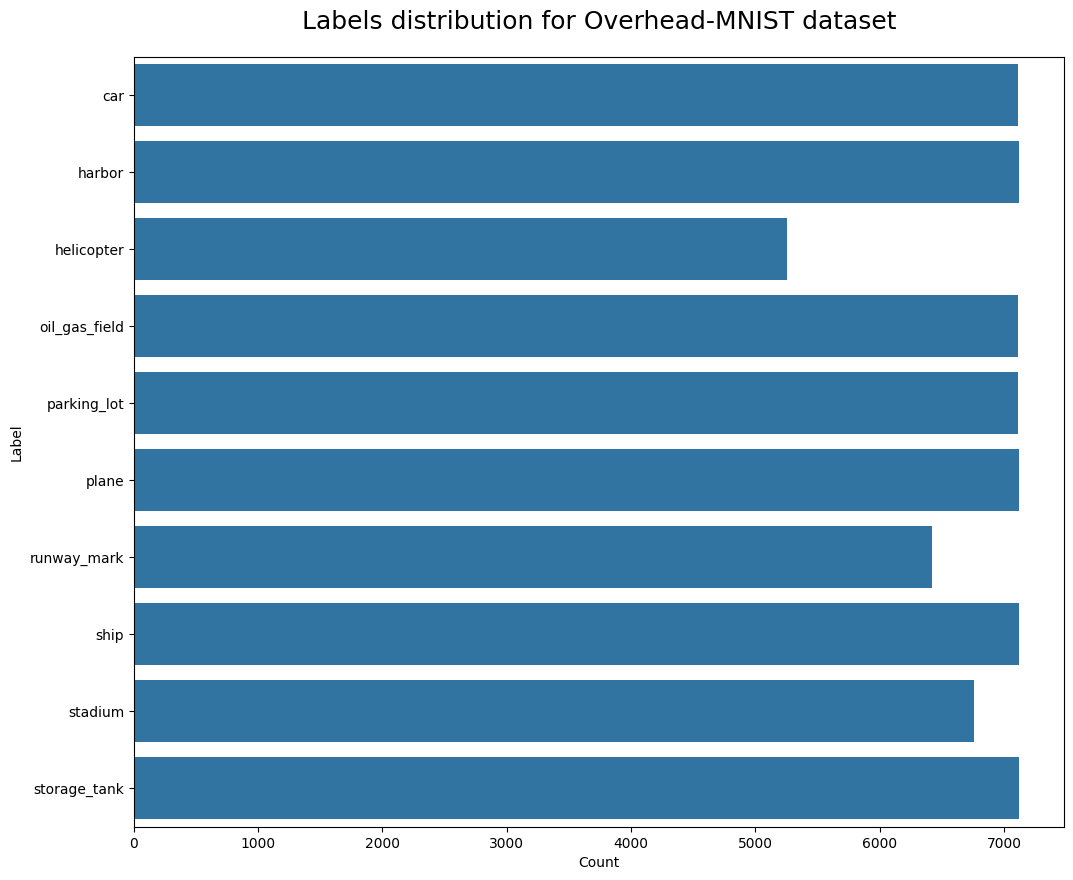

In [17]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/overhead-mnist/train/"
}

train_dataset = OverheadMNISTDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/overhead-mnist/test/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = OverheadMNISTDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(68257, 8520)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/overhead-mnist/"
model_config = {
    "num_classes": 10, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 12:16:47,630 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 12:16:47,810 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [14]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 12:16:50,108 INFO Starting training.
training: 100%|██████████| 2134/2134 [13:10<00:00,  2.70it/s]
2025-05-20 12:30:00,367 INFO epoch: 1, time: 790, loss:  0.14839
testing on train set: 100%|██████████| 2134/2134 [03:04<00:00, 11.56it/s]
2025-05-20 12:33:06,714 INFO Accuracy:0.9783318926996498, Precision Micro:0.9783318926996498, Precision Macro:0.9780481881973866, Precision Weighted:0.9787279571197126, Precision per Class:[0.99886299 0.98661088 0.95356946 0.950411   0.97899583 0.99603848
 0.99356189 0.99729999 0.94729283 0.97783854], Recall Micro:0.9783318926996498, Recall Macro:0.9784503722174474, Recall Weighted:0.9783318926996498, Recall per Class:[0.9876335  0.99367889 0.98971429 0.99156474 0.95696808 0.98820887
 0.96107738 0.98512072 0.97631735 0.95421991], F1_score Micro:0.9783318926996493, F1_score Macro:0.9780864801908326, F1_score Weighted:0.978373296887887, F1_score per Class:[0.99321651 0.99013227 0.97130573 0.97055181 0.96785663 0.99210823
 0.9770497  0.99117294

0.03127004720511948

## Predictions

2025-05-20 14:27:23,780 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/overhead-mnist/checkpoint.pth.tar
2025-05-20 14:27:24,003 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/overhead-mnist/checkpoint.pth.tar at epoch 11


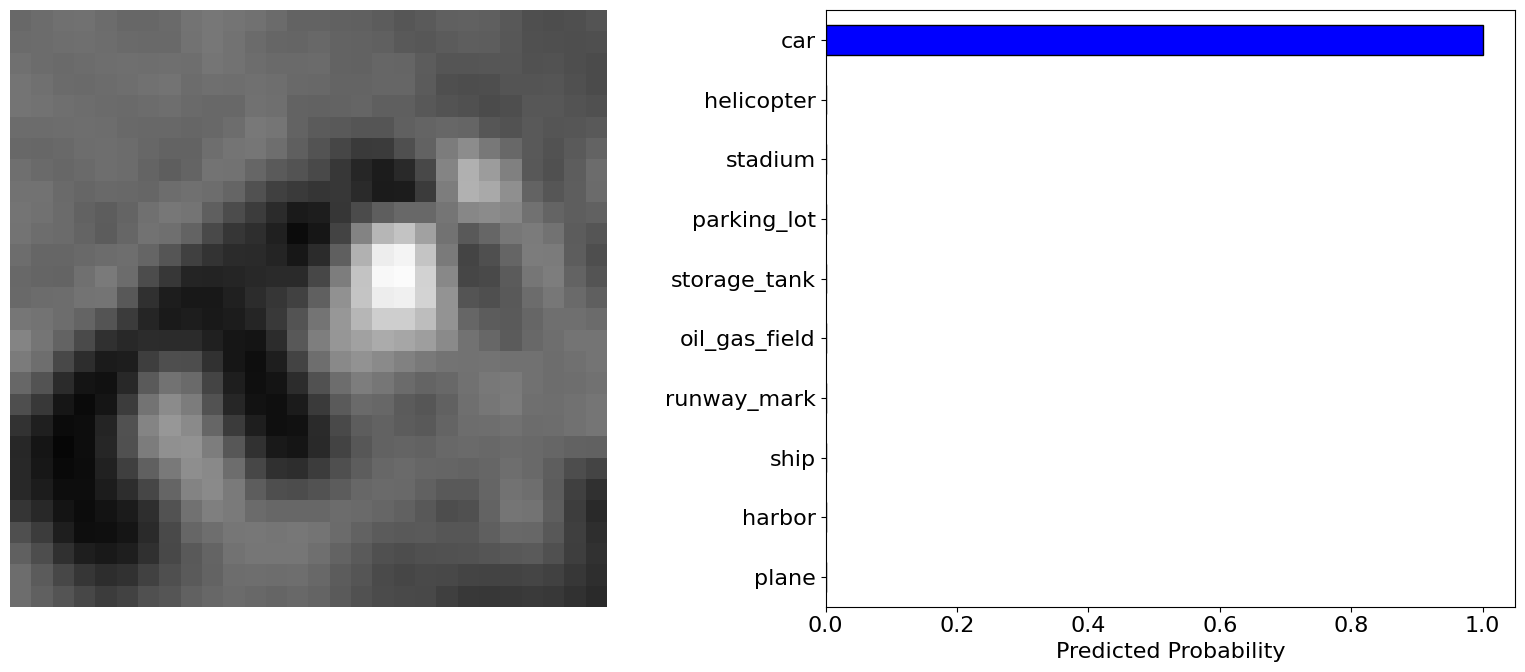

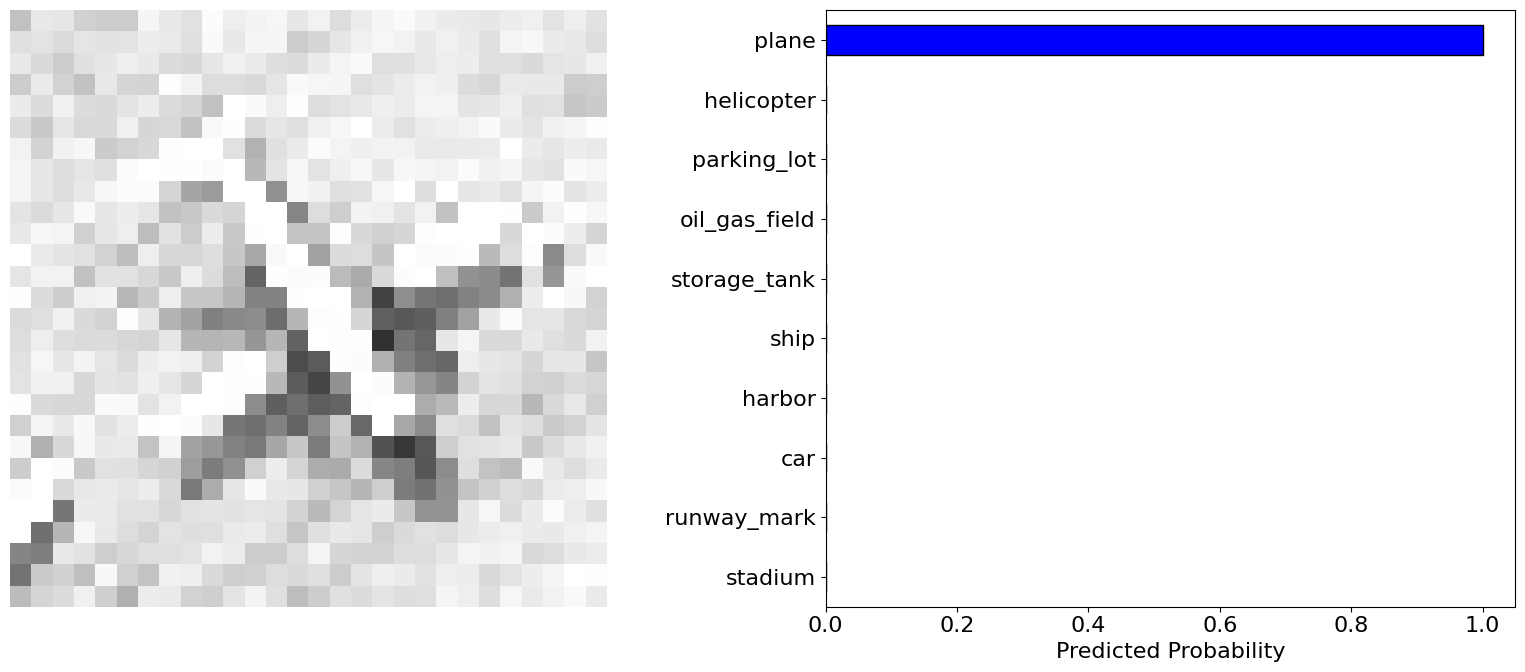

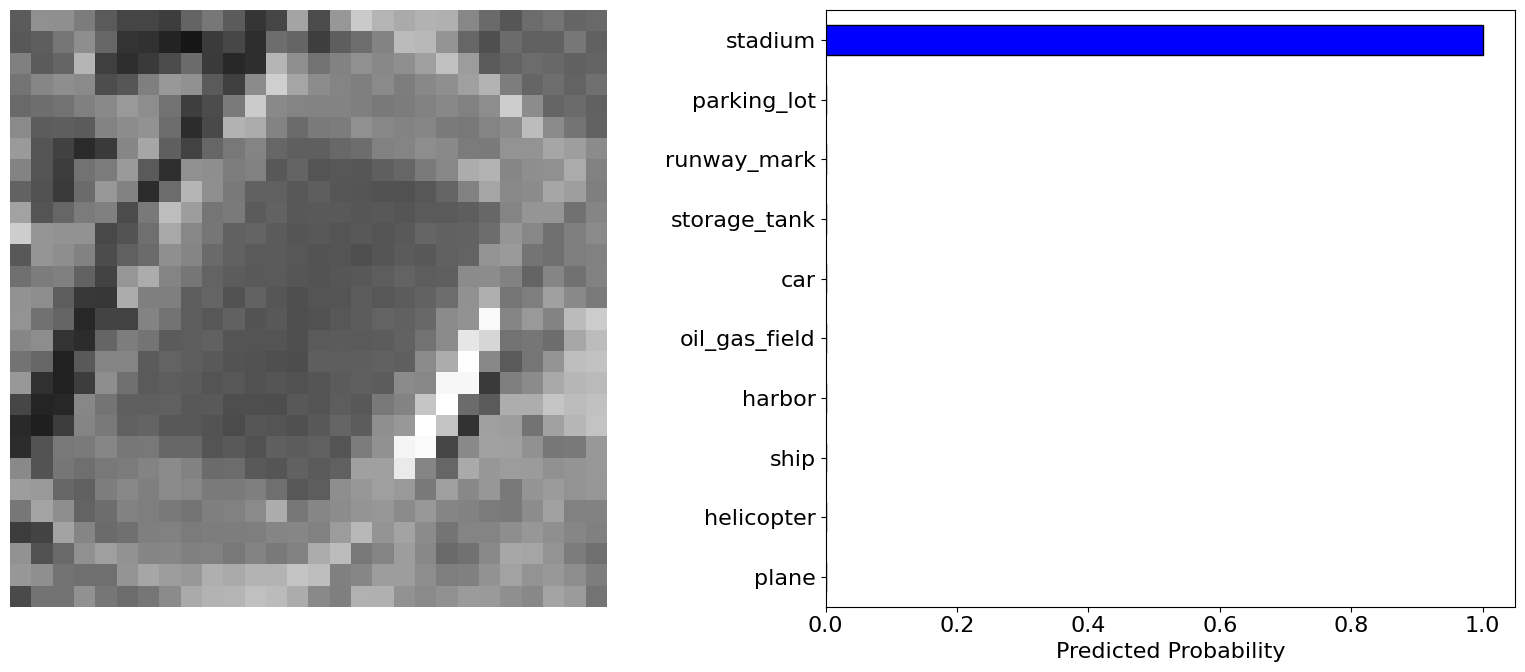

In [ ]:
labels = ["car","harbor","helicopter","oil_gas_field","parking_lot","plane","runway_mark","ship","stadium","storage_tank"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/overhead-mnist/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/overhead-mnist/test/car/68197.jpg')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/overhead-mnist/test/plane/68247.jpg')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/overhead-mnist/test/stadium/68260.jpg')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)